In [14]:
import pandas as pd
import numpy as np5
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

In [15]:
df = pd.read_excel(r"D:\stockprice.xlsx")
print("Loaded:", df.shape)
print(df.head())
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df.dropna(subset=["Date", "Close"], inplace=True)
df.reset_index(drop=True, inplace=True)
print("\nRows per company:")
print(df["Company"].value_counts().head())

Loaded: (1999, 9)
                        Date        Open        High         Low       Close  \
0  2018-11-29 00:00:00-05:00   43.829761   43.863354   42.639594   43.083508   
1  2018-11-29 00:00:00-05:00  104.769074  105.519257  103.534595  104.636131   
2  2018-11-29 00:00:00-05:00   54.176498   55.007500   54.099998   54.729000   
3  2018-11-29 00:00:00-05:00   83.749496   84.499496   82.616501   83.678497   
4  2018-11-29 00:00:00-05:00   39.692784   40.064904   38.735195   39.037853   

      Volume  Dividends  Stock Splits Company  
0  167080000       0.00             0    AAPL  
1   28123200       0.00             0    MSFT  
2   31004000       0.00             0   GOOGL  
3  132264000       0.00             0    AMZN  
4   54917200       0.04             0    NVDA  

Rows per company:
Company
AAPL    5
GILD    5
MMC     5
MDLZ    5
AMT     5
Name: count, dtype: int64


In [16]:
numeric_features = ["Open", "High", "Low", "Volume", "Dividends", "Stock Splits"]
company_dummies = pd.get_dummies(df["Company"], prefix="Co", dtype=int)
X = pd.concat([df[numeric_features], company_dummies], axis=1)
y = df["Close"]
print("Feature matrix shape:", X.shape)
print("Target shape        :", y.shape)

Feature matrix shape: (1999, 464)
Target shape        : (1999,)


In [17]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print(f"\nTrain: {len(X_train)} | Test: {len(X_test)}")
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

model = LinearRegression()
model.fit(X_train_s, y_train)
print("\nModel trained")



Train: 1599 | Test: 400

Model trained


In [18]:

y_pred = model.predict(X_test_s)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred) if len(y_test) >= 2 else float("nan")

print("\n================================")
print("MODEL PERFORMANCE")
print("================================")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R2   : {r2:.4f}")


MODEL PERFORMANCE
MAE  : 1.2130
RMSE : 4.2524
R2   : 0.9994


In [19]:
latest = df.sort_values("Date").groupby("Company").tail(1).copy()

latest_X = pd.concat(
    [latest[numeric_features],
     pd.get_dummies(latest["Company"], prefix="Co", dtype=int)],
    axis=1
)

latest_X = latest_X.reindex(columns=X.columns, fill_value=0)

latest_X_s = scaler.transform(latest_X)
latest["Predicted_Close"] = model.predict(latest_X_s)

print("\nPredicted Close - sample:")
print(latest[["Company", "Close", "Predicted_Close"]].head(10))



Predicted Close - sample:
     Company       Close  Predicted_Close
1678     PRU   69.295525        69.753307
1679     LVS   50.696789        50.700688
1680     LYG    2.279109         2.290811
1681     FIS   97.424927        98.153296
1686     WCN   75.075043        75.747259
1683     TTD   14.011000        14.233461
1684    CSGP   36.582001        36.304128
1685    FERG   55.773399        55.907214
1677     MFC   12.489460        12.555943
1682    VRSK  116.698265       118.344471


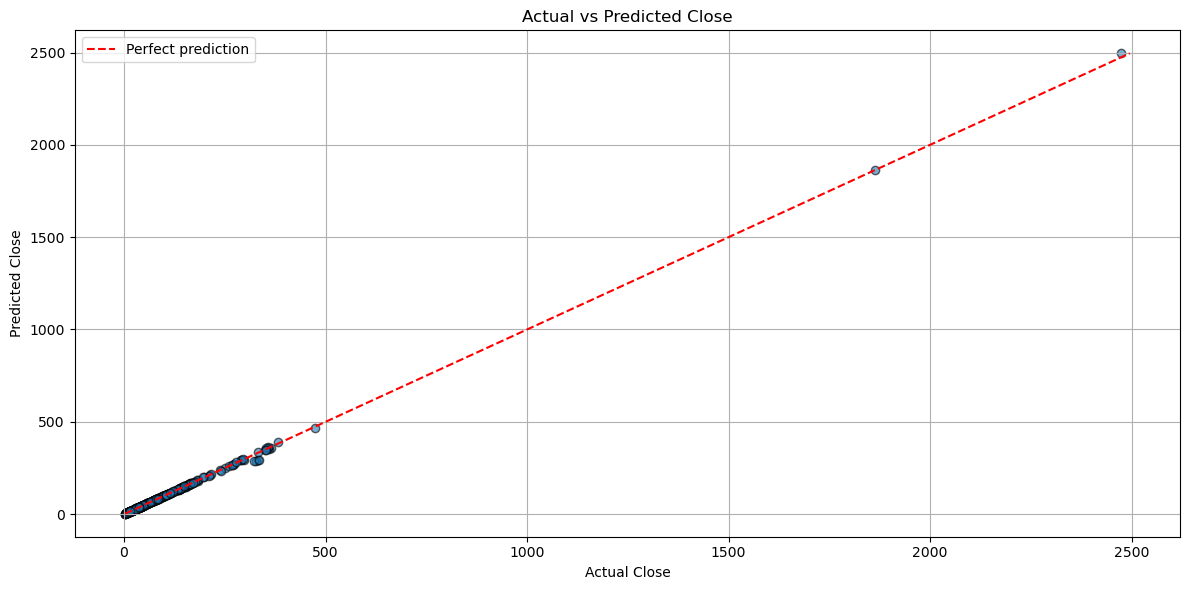

In [20]:

plt.figure(figsize=(12, 6))
plt.scatter(y_test, y_pred, alpha=0.6, edgecolor="k")
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual Close")
plt.ylabel("Predicted Close")
plt.title("Actual vs Predicted Close")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [21]:
top = latest.sort_values("Predicted_Close", ascending=False).head(15)
x = np.arange(len(top))

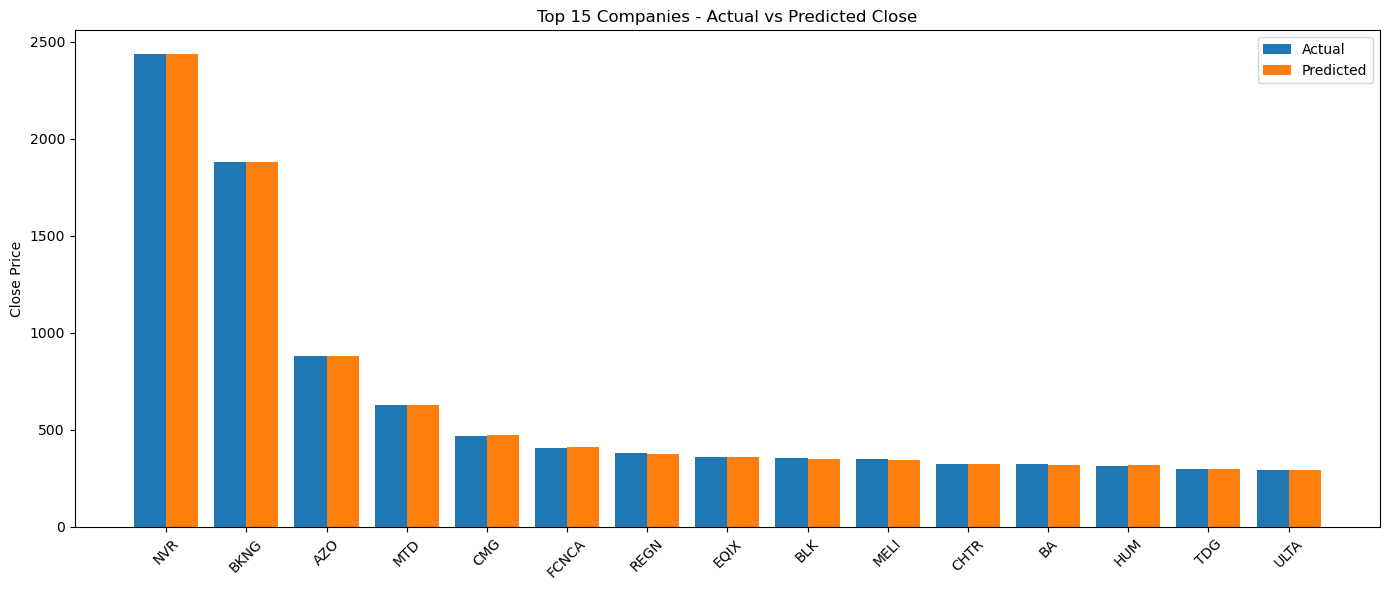

In [22]:
plt.figure(figsize=(14, 6))
plt.bar(x - 0.2, top["Close"], width=0.4, label="Actual")
plt.bar(x + 0.2, top["Predicted_Close"], width=0.4, label="Predicted")
plt.xticks(x, top["Company"], rotation=45)
plt.ylabel("Close Price")
plt.title("Top 15 Companies - Actual vs Predicted Close")
plt.legend()
plt.tight_layout()
plt.show()